# FinGuard 02: Advanced Features
Builds on notebook 01. Each section demonstrates one feature added to move FinGuard closer to a real system.

1. **Time-based evaluation** (train on the past, test on the future) and 10 models including XGBoost and LightGBM
2. **Hyper-parameter tuning** with randomised search
3. **Probability calibration** (so "30%" means about 30%)
4. **Mule-account detection** from the transaction network (graph features)
5. **Fairness audit** of the loan model
6. **Drift monitoring** with PSI
7. **Retraining from analyst feedback**

All data is synthetic (see README). Run notebook 01 first so the models in `models/` exist.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from IPython.display import display, Image
import train_utils as tu, graph_module as gm, fairness as fa, monitoring as mon, retrain as rt
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 30)

upi = pd.read_csv(ROOT / "data" / "upi_transactions.csv")
TARGET, DROP = "is_fraud", ["txn_id", "fraud_type"]
pre, feats = tu.make_preprocessor(upi, TARGET, DROP)
X, y = upi[feats], upi[TARGET]
pos_weight = float((y == 0).sum() / (y == 1).sum())
print("rows:", len(upi), "| features:", len(feats), "| pos_weight:", round(pos_weight, 1))

rows: 30000 | features: 21 | pos_weight: 56.9


## 1. Time-based evaluation
A random split lets the model see tomorrow's patterns while training. A real system only knows the past, so we train on the earliest 70% of transactions (by `txn_time`) and test on the latest 30%.

In [2]:
tr_idx, te_idx = tu.time_split(upi, "txn_time", 0.7)
Xtr, ytr, Xte, yte = X.loc[tr_idx], y.loc[tr_idx], X.loc[te_idx], y.loc[te_idx]
print("train:", upi.loc[tr_idx, "txn_time"].min()[:10], "->", upi.loc[tr_idx, "txn_time"].max()[:10], f"({len(Xtr)} rows, {int(ytr.sum())} fraud)")
print("test :", upi.loc[te_idx, "txn_time"].min()[:10], "->", upi.loc[te_idx, "txn_time"].max()[:10], f"({len(Xte)} rows, {int(yte.sum())} fraud)")

models = tu.get_models("class_weight", pos_weight=pos_weight, boosting=True)
fitted, scores = tu.fit_all_holdout(Xtr, ytr, Xte, pre, models)
tbl = pd.DataFrame({n: tu.holdout_metrics(yte, s) for n, s in scores.items()}).T.sort_values("PR-AUC", ascending=False)
tbl.round(4).to_csv(tu.REPORTS_DIR / "upi_timesplit_metrics.csv")
tbl.round(4)

train: 2026-07-01 -> 2026-09-01 (21000 rows, 364 fraud)
test : 2026-09-01 -> 2026-09-28 (9000 rows, 154 fraud)


,Precision,Recall,F1,ROC-AUC,PR-AUC,Log-loss,KS
Random Forest,0.9779,0.8636,0.9172,0.9396,0.8786,0.0337,0.8695
LightGBM,0.9852,0.8636,0.9204,0.9298,0.8768,0.0314,0.8699
XGBoost,0.9708,0.8636,0.9141,0.9278,0.8759,0.0219,0.8671
AdaBoost,0.9732,0.7078,0.8195,0.9313,0.8740,0.3089,0.8740
MLP,0.8837,0.7403,0.8057,0.9250,0.8345,0.0278,0.8507
Decision Tree,0.2762,0.8377,0.4155,0.9141,0.7996,0.1246,0.8287
kNN,1.0000,0.5325,0.6949,0.9223,0.7804,0.0491,0.8016
Logistic Regression,0.2165,0.8701,0.3467,0.9312,0.6925,0.2023,0.8468
SVM (RBF),0.7864,0.5260,0.6304,0.9287,0.6901,0.0388,0.8404
Naive Bayes,0.3660,0.3636,0.3648,0.9281,0.3225,0.2503,0.8035


Random Forest PR-AUC  random split: 0.872 | time split: 0.879


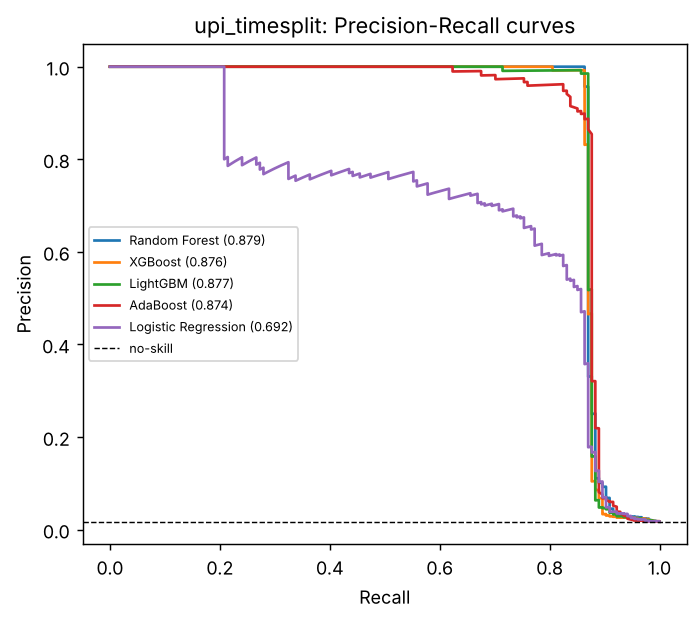

In [3]:
# same Random Forest, random split vs time split
from sklearn.model_selection import train_test_split
Xa, Xb, ya, yb = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)
rf_rand = tu.build_pipeline(clone(pre), models["Random Forest"]).fit(Xa, ya)
m_rand = tu.holdout_metrics(yb, rf_rand.predict_proba(Xb)[:, 1])
m_time = tbl.loc["Random Forest"]
print(f"Random Forest PR-AUC  random split: {m_rand['PR-AUC']:.3f} | time split: {m_time['PR-AUC']:.3f}")
tu.plot_roc_pr({k: scores[k] for k in ["Random Forest", "XGBoost", "LightGBM", "AdaBoost", "Logistic Regression"]}, yte, "upi_timesplit")
display(Image(str(tu.REPORTS_DIR / "upi_timesplit_pr.png")))

## 2. Hyper-parameter tuning
Randomised search (12 candidates, 3-fold CV, scored by PR-AUC) on the **training** period only; the test period is touched once at the end.

In [4]:
rows, tuned = [], {}
for name in ["Random Forest", "XGBoost", "LightGBM"]:
    base = tu.build_pipeline(clone(pre), models[name])
    best, res = tu.tune_model(base, Xtr, ytr, name, n_iter=12)
    tuned[name] = best
    s_def, s_tun = scores[name], best.predict_proba(Xte)[:, 1]
    rows.append({"Model": name, "CV PR-AUC (best)": round(res.loc[0, "mean_test_score"], 4),
                 "test PR-AUC default": round(tu.holdout_metrics(yte, s_def)["PR-AUC"], 4),
                 "test PR-AUC tuned": round(tu.holdout_metrics(yte, s_tun)["PR-AUC"], 4),
                 "best params": {k.replace("clf__", ""): v for k, v in res.loc[0, "params"].items()}})
tune_tbl = pd.DataFrame(rows); tune_tbl.drop(columns="best params").to_csv(tu.REPORTS_DIR / "upi_tuning.csv", index=False)
display(tune_tbl.drop(columns="best params")); 
for r in rows: print(r["Model"], "->", r["best params"])

,Model,CV PR-AUC (best),test PR-AUC default,test PR-AUC tuned
0,Random Forest,0.8754,0.8786,0.8782
1,XGBoost,0.8751,0.8759,0.8757
2,LightGBM,0.8750,0.8768,0.8755


Random Forest -> {'n_estimators': 500, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 20}
XGBoost -> {'subsample': 0.8, 'n_estimators': 300, 'min_child_weight': 3, 'max_depth': 8, 'learning_rate': 0.03, 'colsample_bytree': 0.6}
LightGBM -> {'subsample': 0.8, 'num_leaves': 63, 'n_estimators': 300, 'min_child_samples': 40, 'learning_rate': 0.03, 'colsample_bytree': 0.6}


## 3. Probability calibration
Class weighting makes a model over-estimate fraud probability. Isotonic calibration rescales the scores so they behave like real probabilities, which matters when a bank sets thresholds or explains a score. Lower Brier score is better.

Brier  raw: 0.0026 | calibrated: 0.0025
PR-AUC raw: 0.8755 | calibrated: 0.8755


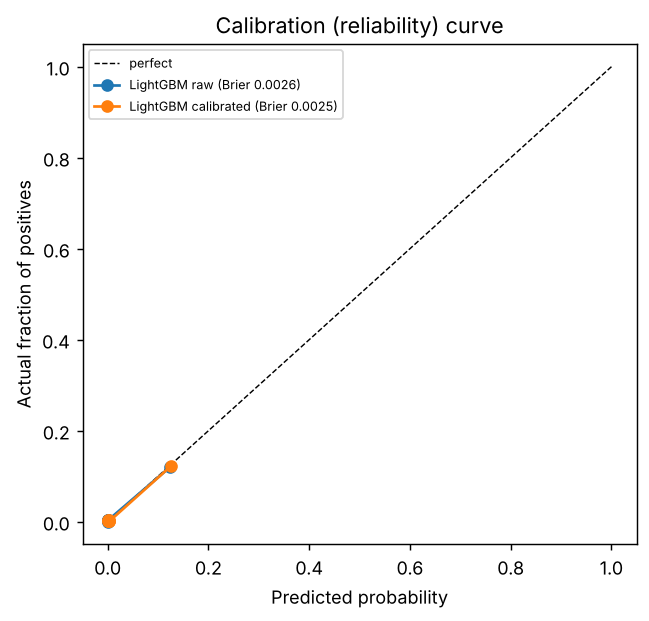

,mean_predicted,actual_fraction_positive
0,0.001,0.001
1,0.001,0.003
2,0.002,0.004
3,0.002,0.002
4,0.002,0.004
5,0.002,0.002
6,0.003,0.001
7,0.125,0.122


In [5]:
from sklearn.metrics import brier_score_loss
lgbm = tuned["LightGBM"]
cal = tu.calibrate_pipeline(clone(lgbm), Xtr, ytr, method="isotonic", cv=3)
s_raw, s_cal = lgbm.predict_proba(Xte)[:, 1], cal.predict_proba(Xte)[:, 1]
print(f"Brier  raw: {brier_score_loss(yte, s_raw):.4f} | calibrated: {brier_score_loss(yte, s_cal):.4f}")
print(f"PR-AUC raw: {tu.holdout_metrics(yte, s_raw)['PR-AUC']:.4f} | calibrated: {tu.holdout_metrics(yte, s_cal)['PR-AUC']:.4f}")
tu.plot_calibration(yte, {"LightGBM raw": s_raw, "LightGBM calibrated": s_cal}, "upi_calibration.png")
display(Image(str(tu.REPORTS_DIR / "upi_calibration.png")))
display(tu.calibration_table(yte, s_cal).round(3))

## 4. Mule-account detection (graph module)
Single payments look harmless; the *pattern across accounts* gives mules away. Features per account: how much of incoming money is passed on, how fast (dwell time), how many "fast-forward" links, and how large a connected group of fast-forward links it belongs to. Legitimate look-alikes (payroll accounts, family members who forward money) are included, so this is not trivial.

In [6]:
edges, accounts = gm.generate_network()
f = gm.graph_features(edges, accounts)
rf_m, table, imp, oof = gm.train_detector(f)
print(f"accounts={len(accounts)}  transfers={len(edges)}  true mules={int(accounts.is_mule.sum())}")
display(table.round(3))
print("Feature importance:"); display(imp.round(3).head(6).to_frame("importance"))

accounts=3000  transfers=24436  true mules=77


,Precision,Recall,F1,PR-AUC,ROC-AUC
"Rule (>=3 fast forwards, >=80% passed on)",0.961,0.636,0.766,NaN,NaN
Random Forest on graph features (5-fold CV),0.884,0.987,0.933,0.993,1.0


Feature importance:


,importance
fast_fwd_count,0.264
fast_fwd_share,0.230
ff_component_size,0.170
median_dwell_min,0.095
n_in,0.092
n_out,0.080


accounts in the largest flagged ring: 19


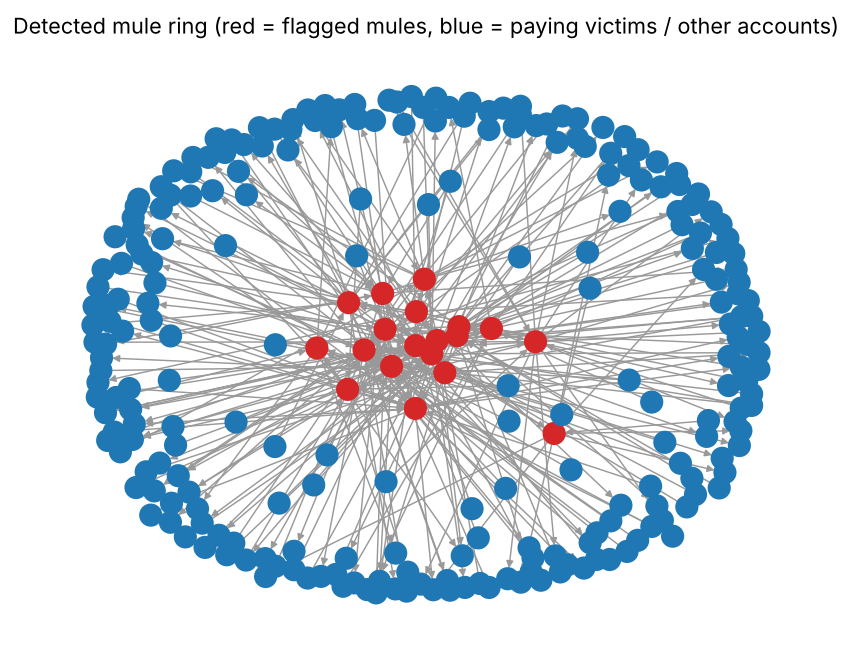

Flagged accounts by true role (non-mules are the false alarms):


,flagged
role,
mule,76
family_forwarder,10


In [7]:
scored = gm.score_accounts(f, rf_m).assign(mule_risk=pd.Series(oof, index=f.index))
n = gm.plot_ring(edges, scored, "mule_network.png")
print("accounts in the largest flagged ring:", n)
display(Image(str(tu.REPORTS_DIR / "mule_network.png")))
flagged = scored[scored.mule_risk >= 0.5]
print("Flagged accounts by true role (non-mules are the false alarms):")
display(flagged["role"].value_counts().to_frame("flagged"))

## 5. Fairness audit (loan model)
`gender` is not a model input. We check outcomes by group anyway, and test whether other inputs act as a proxy for it.

In [8]:
from sklearn.model_selection import train_test_split
cr = pd.read_csv(ROOT / "data" / "credit_risk.csv")
cm = tu.load_model("credit_risk_rf")
Xc, yc = cr[cm["features"]], cr["default"]
_, Xct, _, yct = train_test_split(Xc, yc, test_size=0.2, stratify=yc, random_state=tu.RANDOM_STATE)
flag = cm["pipeline"].predict_proba(Xct)[:, 1] >= cm["threshold"]
for name, g in [("gender", cr.loc[Xct.index, "gender"].values), ("age group", fa.age_group(cr.loc[Xct.index, "age"]).values)]:
    rep, ref = fa.group_report(yct, flag, g)
    print(f"--- {name} (reference group: {ref})"); display(rep)
    rep.to_csv(tu.REPORTS_DIR / f"fairness_{name.split()[0]}.csv")
auc = fa.proxy_auc(pd.get_dummies(Xc, drop_first=True), cr["gender"])
print(f"Proxy check: predicting gender from the model inputs gives AUC = {auc:.3f} (0.5 = no leakage of gender)")

--- gender (reference group: M)


,n,actual_default_rate,approval_rate,TPR,FPR,disparate_impact,TPR_gap_vs_ref,FPR_gap_vs_ref,passes_4/5_rule
group,,,,,,,,,
F,1176,0.087,0.874,0.471,0.093,0.992,0.087,0.005,True
M,1824,0.101,0.882,0.384,0.088,1.000,0.000,0.000,True


--- age group (reference group: <30)


,n,actual_default_rate,approval_rate,TPR,FPR,disparate_impact,TPR_gap_vs_ref,FPR_gap_vs_ref,passes_4/5_rule
group,,,,,,,,,
30-44,964,0.090,0.874,0.379,0.100,0.970,0.040,0.027,True
45-59,863,0.101,0.877,0.460,0.085,0.973,0.120,0.012,True
60+,614,0.098,0.866,0.467,0.097,0.961,0.127,0.024,True
<30,559,0.095,0.902,0.340,0.073,1.000,0.000,0.000,True


Proxy check: predicting gender from the model inputs gives AUC = 0.501 (0.5 = no leakage of gender)


## 6. Drift monitoring (PSI)
We compare recent transactions with the training data. A batch from the same period should be stable; a batch where amounts, hours and payee types have shifted should be flagged.

In [9]:
ref = Xtr.sample(8000, random_state=1)
same = Xte.sample(3000, random_state=2)
shifted = same.copy()
shifted["amount"] *= 3; shifted["hour"] = (shifted["hour"] + 6) % 24
shifted["payee_category"] = np.where(np.random.default_rng(0).random(len(shifted)) < .4, "other", shifted["payee_category"])
cols = ["amount", "hour", "payee_category", "txn_count_24h", "location_match", "device_changed"]
print("Normal batch:"); display(mon.drift_report(ref, same, cols))
print("Shifted batch:"); display(mon.drift_report(ref, shifted, cols))
rp = fitted["Random Forest"]
print("Score drift, normal :", mon.score_drift(rp.predict_proba(ref)[:, 1], rp.predict_proba(same)[:, 1]))
print("Score drift, shifted:", mon.score_drift(rp.predict_proba(ref)[:, 1], rp.predict_proba(shifted)[:, 1]))

Normal batch:


,feature,psi,status
0,hour,0.0056,stable
1,amount,0.0052,stable
2,txn_count_24h,0.0013,stable
3,payee_category,0.0012,stable
4,device_changed,0.0008,stable
5,location_match,0.0001,stable


Shifted batch:


,feature,psi,status
0,amount,1.2546,DRIFT
1,hour,0.7791,DRIFT
2,payee_category,0.7558,DRIFT
3,txn_count_24h,0.0013,stable
4,device_changed,0.0008,stable
5,location_match,0.0001,stable


Score drift, normal : {'psi': 0.022, 'status': 'stable'}
Score drift, shifted: {'psi': 0.9332, 'status': 'DRIFT'}


## 7. Retraining from analyst feedback
In the app, analysts mark flagged transactions as *confirmed fraud* or *genuine customer*. Here we simulate that feedback (labels from the ground truth, as an analyst would give) and run the retraining comparison. The new model is evaluated on a held-out half that analysts never see, and is promoted only if it is not worse. This is a **dry run**: it changes nothing on disk.

In [10]:
m = tu.load_model("upi_fraud_rf")
_, Xt_all, _, _ = train_test_split(upi[m["features"]], upi[TARGET], test_size=0.2, stratify=upi[TARGET], random_state=tu.RANDOM_STATE)
live, ev = tu.live_eval_split(Xt_all.index)
s_live = m["pipeline"].predict_proba(Xt_all.loc[live])[:, 1]
ids = live[s_live >= m["tiers"]["verify"]]
fb = pd.DataFrame({"txn_id": upi.loc[ids, "txn_id"].values, "label": upi.loc[ids, TARGET].values})
print(f"simulated analyst feedback: {len(fb)} reviewed cases, {int(fb.label.sum())} confirmed fraud")
res = rt.retrain(feedback=fb, dry_run=True, verbose=False); res

simulated analyst feedback: 154 reviewed cases, 46 confirmed fraud


{'status': 'compared',
 'n_feedback': 154,
 'old_PR_AUC': 0.8415,
 'new_PR_AUC': 0.8458,
 'old_F1': 0.9032,
 'new_F1': 0.9032,
 'promote': True}

## 8. Summary
Fill in from the tables above: how much worse (or not) the time-split result is than a random split, which model won after tuning, calibration improvement (Brier), mule-detector precision/recall vs the simple rule, fairness findings, drift behaviour, and the effect of analyst feedback. Remember to state that all data is synthetic.